# 03 - Model Training & Evaluation

基于构造好的特征，训练 LightGBM 二分类模型：
- 数据集划分（Train / Val / Test）
- 类别不平衡处理（`scale_pos_weight`）
- LightGBM 训练 + Early Stopping
- 评估：AUC-ROC、PR Curve、混淆矩阵
- 模型解释：Feature Importance + SHAP
- 模型保存

In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import pandas as pd
import numpy as np
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

PROCESSED_DIR = "./data/processed"
MODEL_DIR = "./models"
os.makedirs(MODEL_DIR, exist_ok=True)

## 1. 加载特征

In [8]:
df = pd.read_parquet(f"{PROCESSED_DIR}/features.parquet")
print(f"Dataset shape  : {df.shape}")
print(f"Positive rate  : {df['label'].mean():.2%}")
df.head(3)

Dataset shape  : (956660, 82)
Positive rate  : 4.87%


,user_active_degree,is_video_author,follow_user_num_x,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,friend_user_num_range,register_days,register_days_range,...,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num,main_category,complete_play_rate,valid_play_rate,like_play_rate,label
0,full_active,1,73,"(50,100]",6,"[1,10)",1,"[1,5)",279,181-365,...,233,0.0,0.0,0.0,0.0,11,0.706917,0.695926,0.006100,0
1,full_active,1,73,"(50,100]",6,"[1,10)",1,"[1,5)",279,181-365,...,1238,0.0,0.0,0.0,0.0,28,0.692902,0.681492,0.023116,0
2,full_active,1,73,"(50,100]",6,"[1,10)",1,"[1,5)",279,181-365,...,782,0.0,0.0,0.0,0.0,9,0.663285,0.776589,0.019536,1


## 2. 数据集划分

按 6:2:2 比例划分，使用 `stratify` 保持各集合正负样本比例一致。

In [ ]:
CAT_COLS = ['user_active_degree', 'video_type', 'upload_type']

# drop 剩余的 object 列（_range 系列分桶字符串）
obj_cols = df.select_dtypes(include='object').columns.tolist()
if obj_cols:
    print(f"Dropping object columns: {obj_cols}")
    df = df.drop(columns=obj_cols)

# 过滤掉已被 drop 的 categorical 列
CAT_COLS = [c for c in CAT_COLS if c in df.columns]
print(f"Effective CAT_COLS: {CAT_COLS}")

X = df.drop('label', axis=1)
y = df['label']

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(f"Train : {X_train.shape[0]:,} ({y_train.mean():.2%} positive)")
print(f"Val   : {X_val.shape[0]:,} ({y_val.mean():.2%} positive)")
print(f"Test  : {X_test.shape[0]:,} ({y_test.mean():.2%} positive)")

Dropping object columns: ['follow_user_num_range', 'fans_user_num_range', 'friend_user_num_range', 'register_days_range', 'visible_status']
Effective CAT_COLS: ['user_active_degree', 'upload_type']
Train : 573,996 (4.87% positive)
Val   : 191,332 (4.87% positive)
Test  : 191,332 (4.87% positive)


## 3. 类别不平衡处理

正样本比例较低（watch_ratio > 2 属于强满意行为），使用 `scale_pos_weight` 对正样本加权，
等价于对损失函数中的正样本损失乘以权重系数。

In [10]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"Train negative : {neg_count:,}")
print(f"Train positive : {pos_count:,}")
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

Train negative : 546,064
Train positive : 27,932
scale_pos_weight: 19.55


## 4. 模型训练

In [11]:
train_data = lgb.Dataset(X_train, label=y_train, categorical_feature=CAT_COLS)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.05,
    'num_leaves': 63,
    'max_depth': -1,
    'min_child_samples': 20,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'scale_pos_weight': scale_pos_weight,
    'verbose': -1,
    'seed': 42,
}

callbacks = [
    lgb.early_stopping(stopping_rounds=50, verbose=True),
    lgb.log_evaluation(period=100),
]

model = lgb.train(
    params,
    train_data,
    num_boost_round=1000,
    valid_sets=[val_data],
    callbacks=callbacks,
)

print(f"\nBest iteration: {model.best_iteration}")
print(f"Best val AUC  : {model.best_score['valid_0']['auc']:.4f}")

Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.87238
[200]	valid_0's auc: 0.874583
Early stopping, best iteration is:
[223]	valid_0's auc: 0.874808

Best iteration: 223
Best val AUC  : 0.8748


## 5. 评估

In [21]:
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)

auc = roc_auc_score(y_test, y_pred_proba)
print(f"Test AUC                : {auc:.4f}")

Test AUC                : 0.8762


IndexError: index 2 is out of bounds for axis 0 with size 2

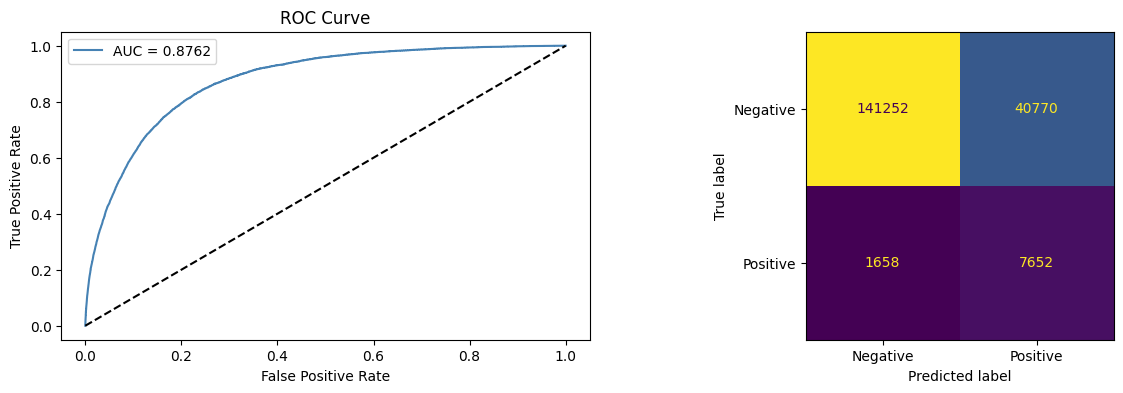

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0].plot(fpr, tpr, color='steelblue', label=f'AUC = {auc:.4f}')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(ax=axes[1], colorbar=False)
axes[1].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

## 6. 特征重要性

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))

lgb.plot_importance(model, ax=ax, max_num_features=20,
                    importance_type='gain', title='Feature Importance (Gain)')

plt.tight_layout()
plt.show()

## 8. 保存模型

In [19]:
model_path = f"{MODEL_DIR}/lgbm_model.pkl"
joblib.dump(model, model_path)
print(f"Model saved to {model_path}")

# 验证可正确加载
loaded_model = joblib.load(model_path)
verify_pred = loaded_model.predict(X_test[:5])
print(f"Verification predictions: {verify_pred.round(4)}")

Model saved to ./models/lgbm_model.pkl
Verification predictions: [0.7574 0.7871 0.0975 0.2706 0.0056]
